In [1]:
# For tips on running notebooks in Google Colab, see
# https://docs.pytorch.org/tutorials/beginner/colab
%matplotlib inline

影像分類器架構

=================================

恭喜！您已經學習了如何定義神經網路（Neural Network）、計算損失（Loss）以及更新網路權重（Weights）。

現在，讓我們將這些理論串聯起來，實際解決一個電腦視覺的經典問題。首先，我們必須思考：

深度學習中的「資料處理」原理是什麼？
---------------------------------------------

機器學習的核心是「數據」。不論是圖像、文字、語音還是影片，神經網路底層**只看得懂張量（Tensor，即多維矩陣）**。因此，我們的第一步永遠是將各種格式的原始數據轉換為張量，並進行「特徵尺度調整（Scaling/Normalization）」。

-   **圖像 (Images)**：通常使用 `Pillow` 或 `OpenCV` 讀取，並轉換為 `[通道數, 高度, 寬度]` (C, H, W) 的張量。
-   **音訊 (Audio)**：使用 `scipy.io.wavfile` 或 `librosa` 將聲波轉換為一維訊號或時頻譜圖矩陣。
-   **文字 (Text)**：將詞彙轉換為索引，再透過嵌入層（Embedding）轉為低維稠密向量。

### 為什麼要使用 `torchvision`？
為了避免大家重複撰寫繁瑣的讀取與預處理程式碼，PyTorch 官方推出了 `torchvision` 套件。它集成了常見的電腦視覺數據集（如 CIFAR10, MNIST）、現成的經典模型架構，以及強大的圖像轉換工具（`transforms`）。

本教學我們將使用 **CIFAR-10** 數據集。它包含 60,000 張 32x32 的 3 通道彩色圖像，共分為 10 個類別（飛機、汽車、鳥、貓、鹿、狗、青蛙、馬、船、卡車）。

![cifar10](https://pytorch.org/tutorials/_static/img/cifar10.png)

---

訓練一個圖像分類器的完整流程
-----------------------------------------

在進入程式碼前，請先建立整體的機器學習 pipeline 觀念。我們將依序執行以下五大核心步驟：

1.  **資料準備 (Data Pipeline)**：使用 `torchvision` 載入 CIFAR10，並將圖像「標準化」，使模型更容易收斂。
2.  **建立模型 (Model Architecture)**：設計一個卷積神經網路（CNN）來自動提取圖像特徵。
3.  **設定目標與方法 (Loss & Optimizer)**：定義衡量預測好壞的「損失函數」與更新參數的「優化算法」。
4.  **模型訓練 (Training Loop)**：讓模型看大量數據，透過「反向傳播（Backpropagation）」不斷修正錯誤。
5.  **模型測試 (Evaluation)**：用模型從未見過的測試集，客觀評估其「泛化能力（Generalization）」。

### 第一步：資料載入與數值歸一化 (Normalization)

在深度學習中，數值歸一化非常重要。若不進行歸一化，圖像像素值（0-255）過大會導致網路在初始化時梯度爆炸或梯度消失，使訓練難以進行。

In [2]:
import torch
import torchvision
from torchvision.transforms import v2

### 預處理背後的數學原理

當我們從 CIFAR-10 載入圖像時，它的原始格式是 PILImage，像素範圍在 `[0, 1]` 區間。我們必須透過變換（Transform）將其轉為張量，並使用以下公式進行 **標準化 (Z-score Normalization)**：

$$\text{output} = \frac{\text{input} - \text{mean}}{\text{std}}$$

在這裡，我們將均值（mean）與標準差（std）都設為 `0.5`。帶入公式：
- 最小值 $0$ 變為：$(0 - 0.5) / 0.5 = -1$
- 最大值 $1$ 變為：$(1 - 0.5) / 0.5 = 1$

這能將輸入數據的分布限制在 `[-1, 1]` 之間，**維持數據的零中心化（Zero-centered）**，能極大加速神經網路的收斂速度。

<div style="background-color: #f0f7f4; border-left: 5px solid #34a853; padding: 15px; margin: 10px 0;">
  <h4 style="margin-top: 0; color: #34a853;">💡 觀念解析：何謂 DataLoader 的 Batch Size 與 Workers？</h4>
  <ul>
    <li><strong>Batch Size (批次大小)</strong>：我們不一次把 50,000 張圖塞給顯卡（記憶體會崩潰），也不一次唯讀一張圖（效率太低）。將資料切成小份量（例如 4 張圖一組）同時計算，稱為 Mini-batch 梯度下降。</li>
    <li><strong>Num Workers (多線程進程數)</strong>：控制用多少個 CPU 核心來平行讀取與預處理圖像，能避免 GPU 在等待數據載入時閒置。如果在 Windows 遇到 <code>RuntimeError</code>，設為 0 代表只使用主線程讀取。</li>
  </ul>
</div>

In [3]:
transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 4

trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

100%|██████████| 170M/170M [41:45<00:00, 68.0kB/s]


為了確保數據載入與轉換無誤，我們通常會在訓練前**視覺化（Visualize）**部分資料，直觀地確認圖像與其對應的標籤（Labels）是否一致。

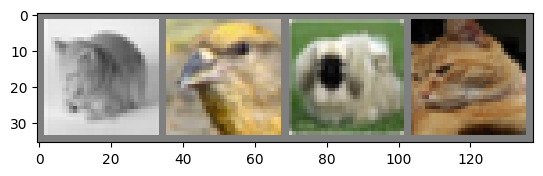

cat   bird  dog   cat  


In [7]:
import matplotlib.pyplot as plt
import numpy as np

# functions to show an image
def imshow(img):
    img = img / 2 + 0.5     # unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()


# get some random training images
dataiter = iter(trainloader)
images, labels = next(dataiter)

# show images
imshow(torchvision.utils.make_grid(images))
# print labels
print(' '.join(f'{classes[labels[j]]:5s}' for j in range(batch_size)))

第二步：設計卷積神經網路 (CNN)
=========================================

### 卷積神經網路如何「看懂」圖像？

傳統的全連接層（Fully Connected Layer）會把圖像拉平成一維向量，這會破壞圖像的**空間幾何結構**（例如：眼睛在鼻子的上方）。而卷積網路（CNN）透過以下三個核心組件解決此問題：

1.  **卷積層 (Convolutional Layer, `nn.Conv2d`)**：
    利用多個可學習的「濾鏡（Filters/Kernels）」在圖像上滑動，提取局部特徵（如邊緣、紋理、形狀）。
    - 第一個參數 `3`：輸入通道數。因為是 RGB 彩色圖，所以是 3。
    - 第二個參數 `6`：輸出通道數（特徵圖數量）。代表我們使用 6 個不同的濾鏡去提取 6 種不同的局部特徵。
    - 第三個參數 `5`：濾鏡的大小為 5x5 像素。

2.  **激活函數 (Activation Function, `F.relu`)**：
    引入**非線性**表達能力。如果沒有非線性激活函數，不論疊多少層網路，其本質都只是單一的線性變換，無法學習複雜的模型。

3.  **最大池化層 (Max Pooling, `nn.MaxPool2d(2, 2)`)**：
    在 2x2 的網格中只保留最大值。這能將特徵圖的尺寸減半，在**減少計算量（降維）**的同時，賦予模型「平移不變性」（即使物體在圖像中稍微移動，提取出的特徵依然相似）。

4.  **全連接層 (Linear Layer, `nn.Linear`)**：
    當圖像經過多層卷積與池化提取出高階特徵後，我們將其「拉平（Flatten）」成一維向量，送入全連接層進行最終的邏輯推理與分類（將特徵映射到 10 個類別機率上）。

In [10]:
import torch.nn as nn
import torch.nn.functional as F


class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 6, 5)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = torch.flatten(x, 1) # flatten all dimensions except batch
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x


net = Net()

第三步：設定損失函數 (Loss) 與優化器 (Optimizer)
======================================================

這一步是在為模型建立「方向指引」與「前進方法」：

### 1. 損失函數：交叉熵 (Cross Entropy Loss)
損失函數用來測量**模型的預測結果與真實標籤之間的差距**。對於多分類問題，我們使用 `nn.CrossEntropyLoss`。它的背後原理是：
- 將模型輸出的「分數（logits）」透過 Softmax 函數轉換成「概率分布」。
- 計算預測機率分布與真實 One-hot 標籤分布之間的**距離**（資訊熵）。距離越近，Loss 越低。

### 2. 優化器：隨機梯度下降 (SGD with Momentum)
優化器決定了**模型如何根據損失來調整自身的權重參數**。
- **梯度 (Gradient)**：損失函數對權重的導數，指向「錯誤增加最快」的方向。我們必須沿著相反的方向（負梯度方向）前進，即「梯度下降」。
- **學習率 (Learning Rate, `lr=0.001`)**：更新參數時的步伐大小。太小收斂極慢，太大則容易跳過最優解甚至導致發散。
- **動量 (Momentum, `0.9`)**：模擬物理世界中的慣性。如果梯度前進方向一致，就加速前進；若方向發生震盪，則能起到平滑緩衝的作用，幫助模型跳出局部最小值（Local Minima）。

In [11]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(net.parameters(), lr=0.001, momentum=0.9)

第四步：執行訓練迴圈 (The Training Loop)
==========================================

這是深度學習最核心的「學習過程」。在每一個訓練步驟中，程式都會執行以下四部曲：

1.  **梯度清零 (`optimizer.zero_grad()`)**：
    在 PyTorch 中，梯度默認是**累加**的（為了方便某些特殊架構如 RNN）。因此，在處理新的批次數據前，我們必須手動將上一輪的梯度清除，否則權重更新方向會出錯。
2.  **前向傳播 (Forward Pass, `outputs = net(inputs)`)**：
    將圖像輸入網路，透過每一層的矩陣乘法與激活函數，計算出預測類別的分數。
3.  **計算損失 (Compute Loss, `loss = criterion(outputs, labels)`)**：
    對比預測分數與真實答案，計算出當前批次的 Loss。
4.  **反向傳播與參數更新 (Backward Pass & Optimization)**：
    - `loss.backward()`：從 Loss 開始逆向追蹤整個計算圖，利用**微積分的連鎖律（Chain Rule）**計算出每個參數對 Loss 的梯度。
    - `optimizer.step()`：優化器根據剛算出來的梯度，依照 SGD 算法公式更新網路中所有的權重（Weights）與偏差（Biases）。

我們重複這個過程 2 個 Epochs（意即整張圖庫完整看過兩次）。

In [12]:
for epoch in range(2):  # loop over the dataset multiple times

    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # get the inputs; data is a list of [inputs, labels]
        inputs, labels = data

        # zero the parameter gradients
        optimizer.zero_grad()

        # forward + backward + optimize
        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        # print statistics
        running_loss += loss.item()
        if i % 2000 == 1999:    # print every 2000 mini-batches
            print(f'[{epoch + 1}, {i + 1:5d}] loss: {running_loss / 2000:.3f}')
            running_loss = 0.0

print('Finished Training')

[1,  2000] loss: 2.254
[1,  4000] loss: 1.870
[1,  6000] loss: 1.675
[1,  8000] loss: 1.578
[1, 10000] loss: 1.538
[1, 12000] loss: 1.494
[2,  2000] loss: 1.428
[2,  4000] loss: 1.376
[2,  6000] loss: 1.361
[2,  8000] loss: 1.340
[2, 10000] loss: 1.294
[2, 12000] loss: 1.271
Finished Training


### 模型的保存與持久化

在實際應用中，訓練可能需要花費數小時甚至數天。因此我們需要把訓練好的參數（網路狀態字典 `state_dict`）保存到硬碟中。這樣以後我們可以直接加載模型來進行預測，而不需要重新訓練。

In [13]:
PATH = './cifar_net.pt'
torch.save(net.state_dict(), PATH)

第五步：在測試數據上評估模型性能
=============================================

### 為什麼需要獨立的「測試集」？
如果我們只在訓練集上評估模型，模型可能會因為「死記硬背」訓練集而拿到 100% 的分數，但遇到新照片時就完全猜錯，這叫做**過擬合 (Overfitting)**。
為了客觀檢驗模型是否真的學到了「如何分辨貓和狗的特徵」，我們必須使用它在訓練過程中**完全沒看過**的測試集進行測試，這衡量的是模型的**泛化能力 (Generalization)**。

讓我們先拿一組測試批次（4 張圖），看看真實的標籤（GroundTruth）是什麼。

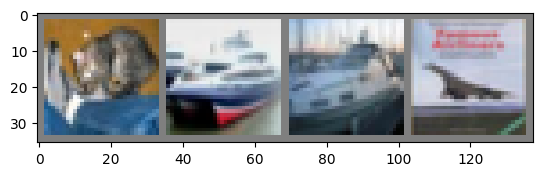

GroundTruth:  cat   ship  ship  plane


In [14]:
dataiter = iter(testloader)
images, labels = next(dataiter)

# print images
imshow(torchvision.utils.make_grid(images))
print('GroundTruth: ', ' '.join(f'{classes[labels[j]]:5s}' for j in range(4)))

現在，我們實例化一個全新的、未經過訓練的網路 `Net()`，並將剛剛儲存的權重檔案載入進去，以此確保我們保存與讀取模型的邏輯是正確的。

In [16]:
net = Net()
net.load_state_dict(torch.load(PATH, weights_only=True))

<All keys matched successfully>

接下來，我們將這 4 張測試影像輸入網路，獲得模型對各種類別的預測分數。

In [17]:
outputs = net(images)

### 預測得分的解讀原理

模型輸出的 `outputs` 是一個大小為 `[4, 10]` 的張量。其中 `4` 是 batch 大小，`10` 是十個類別的預測得分（Logits）。
雖然這些數值尚未通過 Softmax 轉成機率，但**數值最大者即代表模型最篤定的分類**。我們使用 `torch.max(outputs, 1)` 來找出每一列（維度 1）中最大值的**索引（Index）**，這個索引對應的就是我們的預測類別。

In [18]:
_, predicted = torch.max(outputs, 1)

print('Predicted: ', ' '.join(f'{classes[predicted[j]]:5s}'
                              for j in range(4)))

Predicted:  cat   ship  ship  ship 


單單看 4 張圖是不夠的，我們必須統計模型在全部 10,000 張測試影像上的**總體準確率 (Overall Accuracy)**。

In [19]:
correct = 0
total = 0
# since we're not training, we don't need to calculate the gradients for our outputs
with torch.no_grad():
    for data in testloader:
        images, labels = data
        # calculate outputs by running images through the network
        outputs = net(images)
        # the class with the highest energy is what we choose as prediction
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f'Accuracy of the network on the 10000 test images: {100 * correct // total} %')

Accuracy of the network on the 10000 test images: 54 %


### 評估結果分析

隨機猜測的基準線（Baseline）是 10%。如果您的模型達到了 50% 以上的準確率，說明模型確實具備了圖像特徵分類的能力！

然而，為了進一步診斷模型，我們需要進行**細分錯誤分析 (Error Analysis)**：分析模型在哪些特定類別上表現優異（例如：飛機、船隻這類背景單純的物體），而在哪些類別上容易混淆（例如：貓、狗這類姿勢多變、外形相似的哺乳類動物）。

In [20]:
# prepare to count predictions for each class
correct_pred = {classname: 0 for classname in classes}
total_pred = {classname: 0 for classname in classes}

# again no gradients needed
with torch.no_grad():
    for data in testloader:
        images, labels = data
        outputs = net(images)
        _, predictions = torch.max(outputs, 1)
        # collect the correct predictions for each class
        for label, prediction in zip(labels, predictions):
            if label == prediction:
                correct_pred[classes[label]] += 1
            total_pred[classes[label]] += 1


# print accuracy for each class
for classname, correct_count in correct_pred.items():
    accuracy = 100 * float(correct_count) / total_pred[classname]
    print(f'Accuracy for class: {classname:5s} is {accuracy:.1f} %')

Accuracy for class: plane is 56.6 %
Accuracy for class: car   is 72.4 %
Accuracy for class: bird  is 32.8 %
Accuracy for class: cat   is 46.4 %
Accuracy for class: deer  is 21.5 %
Accuracy for class: dog   is 37.6 %
Accuracy for class: frog  is 71.8 %
Accuracy for class: horse is 72.1 %
Accuracy for class: ship  is 80.1 %
Accuracy for class: truck is 51.4 %


第六步：使用 GPU (CUDA) 加速訓練
=========================================

### 為什麼 GPU 比 CPU 適合深度學習？
- **CPU**（中央處理器）像是一位「天才數學家」，擅長處理複雜的邏輯控制和順序計算，但核心數較少（通常 4 到 64 核）。
- **GPU**（圖形處理器）則像是由「幾千名小學生」組成的矩陣，雖然每個人只能做簡單的加減乘除，但人數極多（數千個 CUDA 核心），能夠並行（Parallel）處理成千上萬個矩陣乘法。

深度學習本質上就是**海量的矩陣乘法**，因此透過 GPU 平行加速，能將訓練時間縮短數十倍甚至數百倍。

首先，我們偵測 Colab 運行環境中是否有可用的 GPU 加速器：

In [21]:
device = torch.device(torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else 'cpu')

# Assuming that we are on a CUDA machine, this should print a CUDA device:

print(device)

cpu


### 如何將運算移至 GPU？

要使用 GPU 加速，我們必須手動將**模型**和**數據**搬運到相同的 GPU 記憶體（VRAM）中：

1.  **移動模型**：
    ```python
    net.to(device)
    ```
    這會遞迴地將網路中的所有權重張量（Weights & Biases）轉換為 CUDA 張量。

2.  **移動數據**（在訓練迴圈的每一個 batch 中）：
    ```python
    inputs, labels = data[0].to(device), data[1].to(device)
    ```

### ⚠️ 常見疑問：為什麼我的模型移到 GPU 後沒有變快？
當模型非常小、資料量很少（例如本教學使用的超迷你 CNN 與 4 的 Batch size）時，將數據從系統記憶體（CPU）搬運到顯卡記憶體（GPU）的**傳輸延遲（PCIe 頻寬限制）**，甚至會大於 GPU 計算節省下來的時間。只有當您**增加網路寬度、深度或加大 Batch Size** 時，GPU 的平行計算優勢才會真正體現出來！

---

下一步與學習資源
=====================

恭喜您完成了 PyTorch 影像分類的完整入門！您可以嘗試以下挑戰來深化理解：
-   **修改網路架構**：嘗試增加卷積層的輸出通道數（例如從 6 增加到 16），看看準確率是否能提升。
-   **調整超參數**：改變學習率（Learning Rate）或增加訓練的 Epochs，觀察 Loss 的下降曲線。
-   **探索進階主題**：
    - [使用 PyTorch 進行強化學習 (RL) 玩遊戲](/intermediate/reinforcement_q_learning)
    - [在 ImageNet 數據集上訓練經典的 ResNet 模型](https://github.com/pytorch/examples/tree/main/imagenet)
    - [生成對抗網路 (GAN)：讓模型自己畫出人臉](https://github.com/pytorch/examples/tree/main/dcgan)

In [ ]:
del dataiter